<a href="https://colab.research.google.com/github/AdwaaNasser/Burnout-Models/blob/main/regression_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Burnout Score Regression — Bayyinah

This notebook builds the model behind Bayyinah's burnout prediction feature. It predicts an employee's burnout score (0–10) from their work and lifestyle data, explains each prediction with SHAP, and saves the model for the Django backend.

**Dataset:** [Mental Health & Burnout in Tech Workers 2026](https://www.kaggle.com/datasets/mohankrishnathalla/mental-health-and-burnout-in-tech-workers-2026) (100,000 employees, 36 columns)
**Preprocessing:** imported from `preprocessing.py` (explained in `preprocessing.ipynb`), shared with the classification notebook.

**Contents**
1. Data
2. Cross-validation setup
3. Model comparison
4. Hyperparameter tuning
5. Test set evaluation
6. Error analysis
7. Permutation importance
8. SHAP explanations
9. Saving the model for Bayyinah

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import sklearn
from scipy.stats import loguniform, randint, uniform

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

from preprocessing import SEED, build_preprocessor, fix_logic, load_and_split

plt.rcParams["figure.dpi"] = 110

## 1. Data

The data exploration and all preprocessing decisions are in `preprocessing.ipynb`. Here we only load the same train/test split.

In [ ]:
X_train, X_test, y_train, y_test = load_and_split()
print("train:", X_train.shape, " test:", X_test.shape)

train: (76804, 27)  test: (19202, 27)


## 2. Cross-validation setup

In [ ]:
# 5 folds stratified on target bins, same as the train/test split
train_bins = pd.qcut(y_train, q=10, labels=False, duplicates="drop")
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, train_bins))


def make_model(estimator):
    # preprocessing is inside the pipeline so it is fitted on the training folds only
    return Pipeline([("prep", build_preprocessor(X_train)), ("model", estimator)])

## 3. Model comparison

In [ ]:
models = {
    "Dummy (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.01, max_iter=5000),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                           max_features=0.5, n_jobs=-1, random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=SEED),
}
scoring = {"MAE": "neg_mean_absolute_error",
           "RMSE": "neg_root_mean_squared_error",
           "R2": "r2"}

results = []
for name, est in models.items():
    scores = cross_validate(make_model(est), X_train, y_train, cv=cv,
                            scoring=scoring, return_train_score=True)
    results.append({
        "model": name,
        "MAE": -scores["test_MAE"].mean(),
        "MAE_std": scores["test_MAE"].std(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R2": scores["test_R2"].mean(),
        "R2_std": scores["test_R2"].std(),
        "train_R2": scores["train_R2"].mean(),
    })

results = pd.DataFrame(results).set_index("model").sort_values("MAE")
results.round(4)

,MAE,MAE_std,RMSE,R2,R2_std,train_R2
model,,,,,,
HistGradientBoosting,0.7877,0.0029,0.9894,0.8625,0.0013,0.8765
Linear Regression,0.7995,0.0027,0.9989,0.8598,0.0012,0.8601
Ridge,0.7995,0.0027,0.9989,0.8598,0.0012,0.8601
Lasso,0.8028,0.0024,1.0021,0.8590,0.0012,0.8590
Random Forest,0.8342,0.0049,1.0432,0.8471,0.0020,0.9373
Dummy (mean),2.2037,0.0020,2.6683,-0.0000,0.0000,0.0000


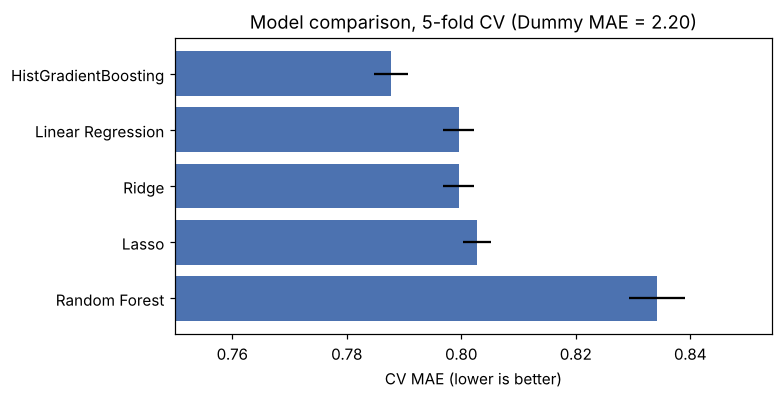

In [ ]:
r = results.drop("Dummy (mean)").sort_values("MAE", ascending=False)
plt.figure(figsize=(7, 3.5))
plt.barh(r.index, r["MAE"], xerr=r["MAE_std"], color="#4C72B0")
plt.xlim(0.75, r["MAE"].max() + 0.02)
plt.xlabel("CV MAE (lower is better)")
plt.title("Model comparison, 5-fold CV (Dummy MAE = %.2f)" % results.loc["Dummy (mean)", "MAE"])
plt.show()

All models beat the Dummy baseline by a wide margin. HistGradientBoosting has the best MAE, RMSE and R², with a small gap between train and validation scores. The linear models are close behind, so the relationship is mostly linear. Random Forest overfits (much higher train R²) and scores lower. We tune HistGradientBoosting and keep Ridge as a simple benchmark.

## 4. Hyperparameter tuning

In [ ]:
# early stopping holds out 10% of the training data it is given, never the test set
hgb = make_model(HistGradientBoostingRegressor(
    early_stopping=True, validation_fraction=0.1, n_iter_no_change=30, random_state=SEED
))
param_dist = {
    "model__learning_rate": loguniform(0.02, 0.3),
    "model__max_iter": randint(200, 1500),
    "model__max_leaf_nodes": randint(8, 64),
    "model__max_depth": [None, 3, 4, 6, 8],
    "model__min_samples_leaf": randint(20, 300),
    "model__l2_regularization": loguniform(1e-3, 10),
    "model__max_features": uniform(0.5, 0.5),
}
search = RandomizedSearchCV(hgb, param_dist, n_iter=30, cv=cv,
                            scoring=scoring, refit="MAE",
                            random_state=SEED, n_jobs=-1)
search.fit(X_train, y_train)

i = search.best_index_
print("best params:", search.best_params_)
print("best CV MAE: ", round(-search.cv_results_["mean_test_MAE"][i], 4))
print("best CV RMSE:", round(-search.cv_results_["mean_test_RMSE"][i], 4))
print("best CV R2:  ", round(search.cv_results_["mean_test_R2"][i], 4))
best_model = search.best_estimator_  # already refitted on the full train set

best params: {'model__l2_regularization': np.float64(0.001158417231054399), 'model__learning_rate': np.float64(0.03737508643922314), 'model__max_depth': 6, 'model__max_features': np.float64(0.7200762468698007), 'model__max_iter': 708, 'model__max_leaf_nodes': 15, 'model__min_samples_leaf': 54}
best CV MAE:  0.7805
best CV RMSE: 0.9802
best CV R2:   0.8651


In [ ]:
top = pd.DataFrame(search.cv_results_).sort_values("rank_test_MAE").head(5)
top = top[["mean_test_MAE", "mean_test_R2"] + [c for c in top.columns if c.startswith("param_")]]
top["mean_test_MAE"] *= -1
top.columns = [c.replace("param_model__", "") for c in top.columns]
top.round(4)

,mean_test_MAE,mean_test_R2,l2_regularization,learning_rate,max_depth,max_features,max_iter,max_leaf_nodes,min_samples_leaf
6,0.7805,0.8651,0.0012,0.0374,6,0.7201,708,15,54
25,0.7807,0.8652,1.6314,0.0715,3,0.8168,951,23,116
15,0.7813,0.8650,0.0774,0.0276,4,0.8804,1441,62,274
27,0.7815,0.8646,0.0248,0.0260,None,0.8455,750,25,148
29,0.7816,0.8650,0.1663,0.0839,3,0.9981,453,19,56


The top configurations score almost the same, so the result does not depend on one lucky combination of settings.

## 5. Test set evaluation

In [ ]:
def evaluate(name, pred):
    return {"model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": root_mean_squared_error(y_test, pred),
            "R2": r2_score(y_test, pred)}


# burnout score is between 0 and 10, so we clip the predictions to that range
hgb_pred = np.clip(best_model.predict(X_test), 0, 10)

test_results = [
    evaluate("Dummy (mean)", make_model(DummyRegressor()).fit(X_train, y_train).predict(X_test)),
    evaluate("Ridge", make_model(Ridge(alpha=1.0)).fit(X_train, y_train).predict(X_test)),
    evaluate("HGB tuned", hgb_pred),
]
test_results = pd.DataFrame(test_results).set_index("model")
test_results.round(4)

,MAE,RMSE,R2
model,,,
Dummy (mean),2.2063,2.6695,-0.0000
Ridge,0.8005,0.9996,0.8598
HGB tuned,0.7755,0.9761,0.8663


In [ ]:
errors = (y_test - hgb_pred).abs()
print(f"within ±0.5 points: {(errors <= 0.5).mean():.1%}")
print(f"within ±1 point:    {(errors <= 1).mean():.1%}")
print(f"within ±2 points:   {(errors <= 2).mean():.1%}")

within ±0.5 points: 39.5%
within ±1 point:    69.2%
within ±2 points:   95.9%


## 6. Error analysis

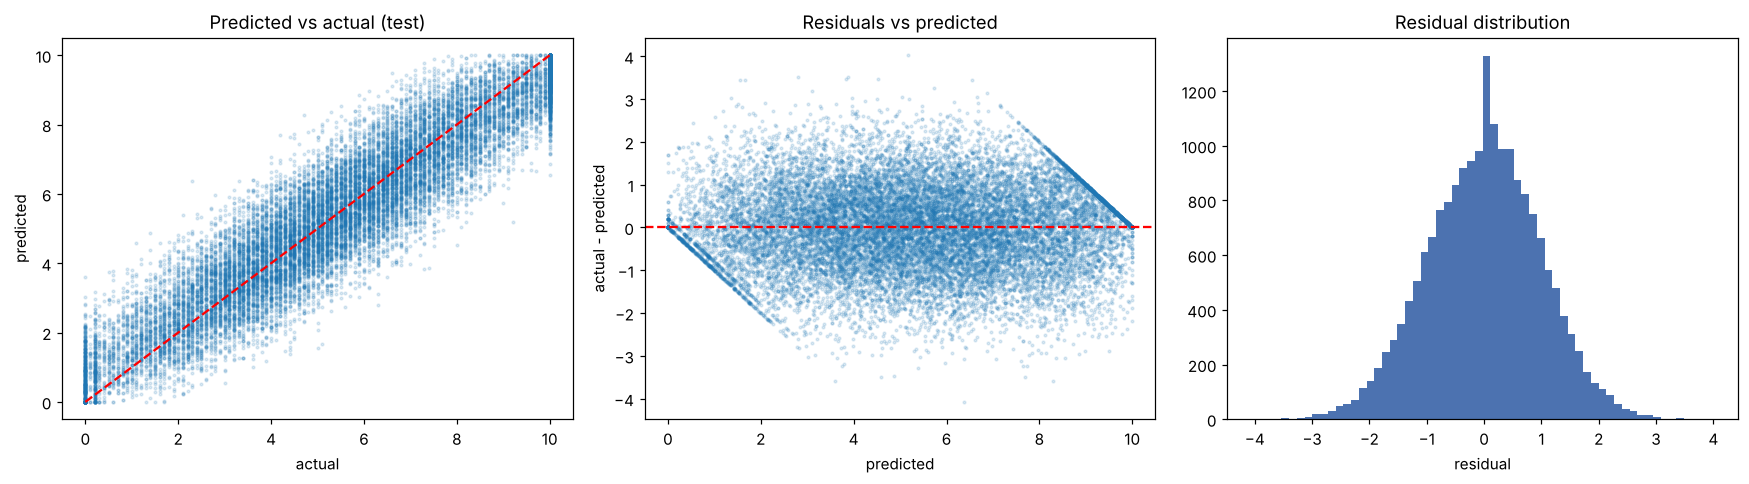

In [ ]:
residuals = y_test - hgb_pred

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(y_test, hgb_pred, s=3, alpha=0.15)
axes[0].plot([0, 10], [0, 10], "r--")
axes[0].set(xlabel="actual", ylabel="predicted", title="Predicted vs actual (test)")
axes[1].scatter(hgb_pred, residuals, s=3, alpha=0.15)
axes[1].axhline(0, color="r", ls="--")
axes[1].set(xlabel="predicted", ylabel="actual - predicted", title="Residuals vs predicted")
axes[2].hist(residuals, bins=60, color="#4C72B0")
axes[2].set(xlabel="residual", title="Residual distribution")
plt.tight_layout()
plt.show()

In [ ]:
bands = pd.cut(y_test, [-0.01, 0, 2, 4, 6, 8, 9.99, 10],
               labels=["0", "0-2", "2-4", "4-6", "6-8", "8-10", "10"])
pd.DataFrame({"bias (actual - pred)": residuals.groupby(bands, observed=True).mean(),
              "MAE": errors.groupby(bands, observed=True).mean(),
              "employees": residuals.groupby(bands, observed=True).size()}).round(3)

,bias (actual - pred),MAE,employees
burnout_score,,,
0,-0.804,0.804,399
0-2,-0.616,0.802,1903
2-4,-0.249,0.781,3840
4-6,-0.052,0.777,5155
6-8,0.159,0.796,4358
8-10,0.518,0.763,2307
10,0.654,0.654,1240


In [ ]:
errors.groupby(X_test["seniority_level"]).mean().round(3).to_frame("MAE by seniority")

,MAE by seniority
seniority_level,
Junior,0.775
Lead,0.741
Manager,0.749
Mid,0.789
Principal,0.773
Senior,0.788


Residuals are centred on zero and roughly bell-shaped. The model pulls predictions toward the middle: very low scores are over-predicted and very high scores are under-predicted. The diagonal lines in the residual plot come from scores capped at 0 and 10. Error is similar across seniority levels.

## 7. Permutation importance

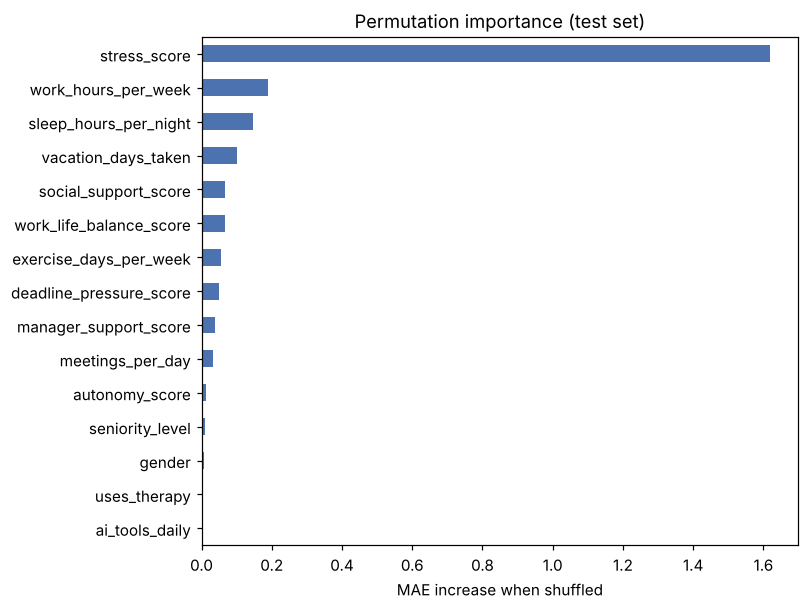

stress_score               1.6183
work_hours_per_week        0.1884
sleep_hours_per_night      0.1453
vacation_days_taken        0.1004
social_support_score       0.0669
work_life_balance_score    0.0665
exercise_days_per_week     0.0555
deadline_pressure_score    0.0489
manager_support_score      0.0395
meetings_per_day           0.0316
dtype: float64

In [ ]:
# how much the MAE increases when we shuffle each feature.
# high importance = the model relies on it, not that it causes burnout
perm = permutation_importance(best_model, X_test, y_test,
                              scoring="neg_mean_absolute_error",
                              n_repeats=10, random_state=SEED, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(7, 6))
importance.tail(15).plot.barh(color="#4C72B0")
plt.xlabel("MAE increase when shuffled")
plt.title("Permutation importance (test set)")
plt.show()
importance.sort_values(ascending=False).round(4).head(10)

## 8. SHAP explanations

Permutation importance tells us which features matter overall. SHAP also shows *how* each feature moves an individual prediction up or down, which is what Bayyinah shows to HR.

In [ ]:
prep = best_model.named_steps["prep"]
hgb_model = best_model.named_steps["model"]

ct = prep.named_steps["columns"]
num_feats = list(ct.transformers_[0][2])
feature_names = [n.split("__", 1)[1] for n in ct.get_feature_names_out()]

sample = X_test.sample(2000, random_state=SEED)
sample_t = prep.transform(sample)

explainer = shap.TreeExplainer(hgb_model)
sv = explainer(sample_t)
sv.feature_names = feature_names
# show real values (hours, scores) on the plots instead of scaled ones
sv.data = np.hstack([fix_logic(sample)[num_feats].values, sample_t[:, len(num_feats):]])

print("average predicted score (SHAP base value):", round(float(sv.base_values[0]), 2))

average predicted score (SHAP base value): 5.39


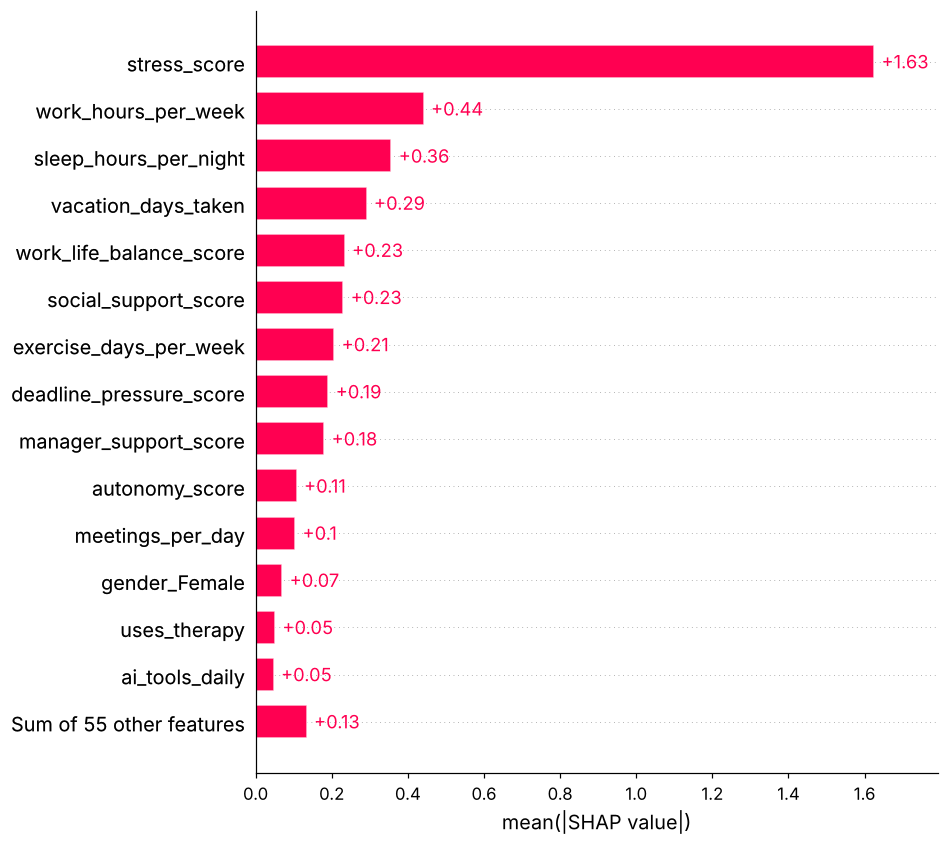

In [ ]:
shap.plots.bar(sv, max_display=15)

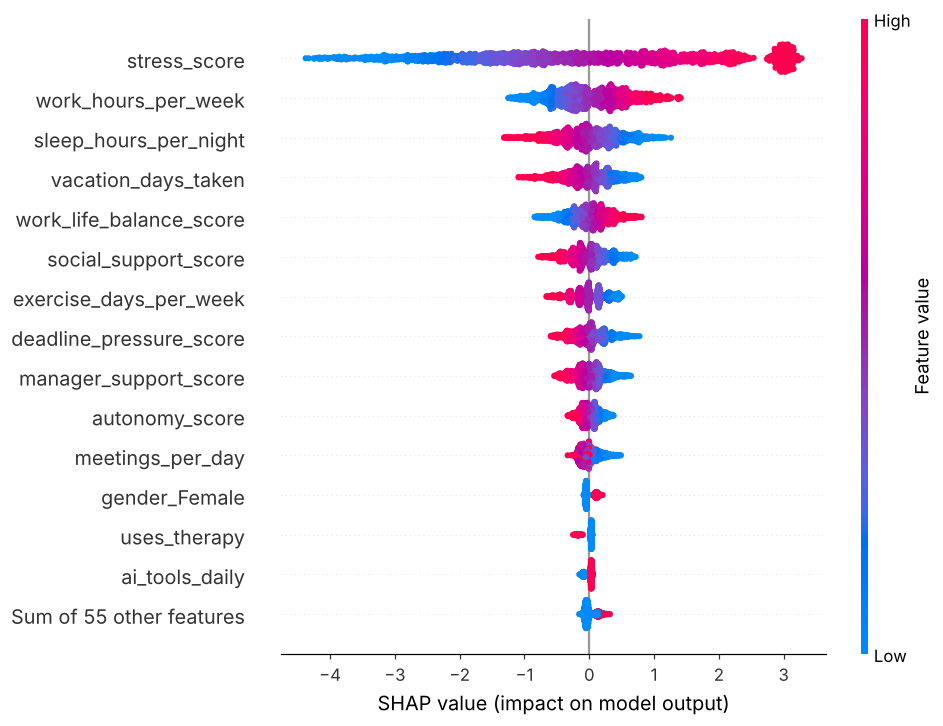

In [ ]:
shap.plots.beeswarm(sv, max_display=15)

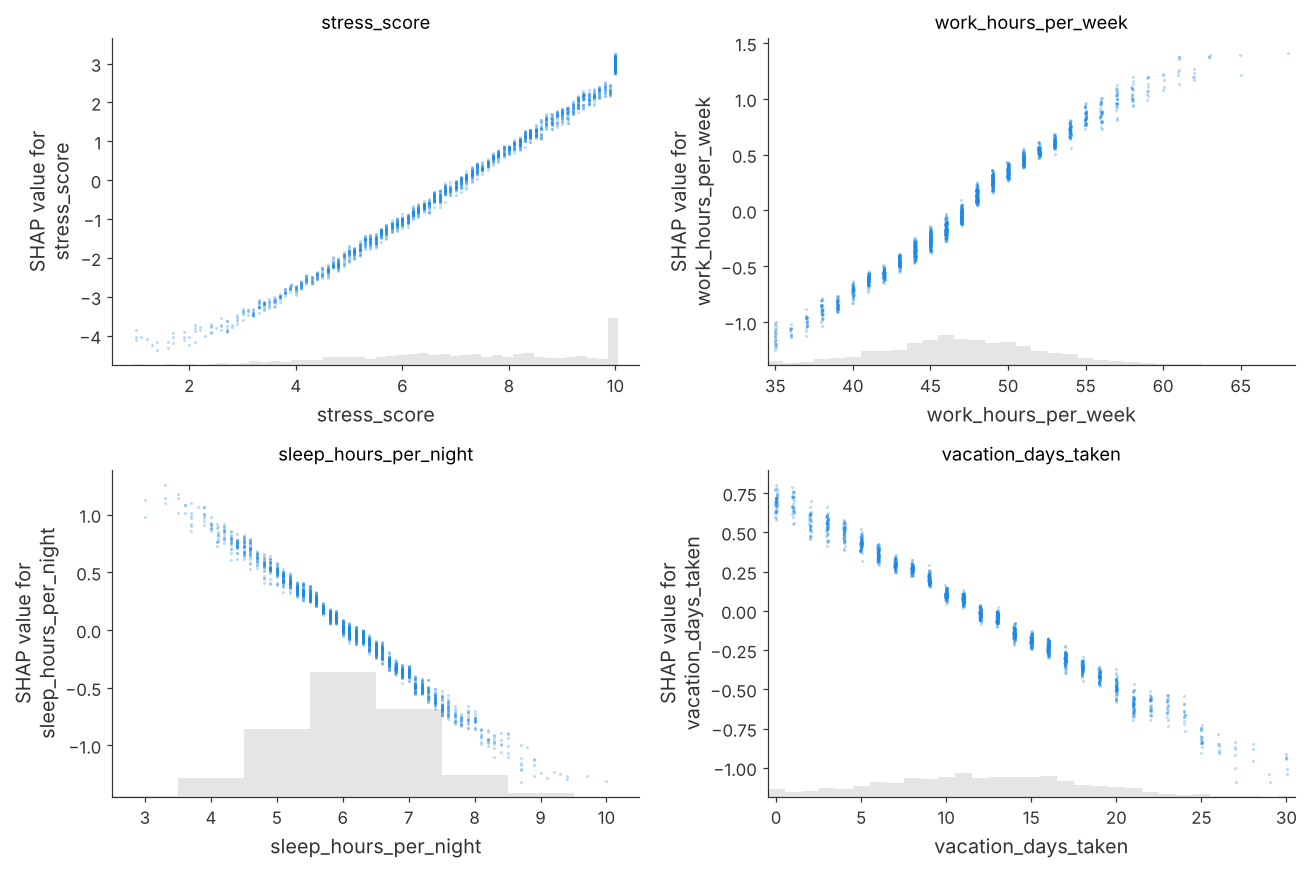

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, f in zip(axes.ravel(), ["stress_score", "work_hours_per_week", "sleep_hours_per_night", "vacation_days_taken"]):
    shap.plots.scatter(sv[:, f], ax=ax, show=False, alpha=0.3, dot_size=4)
    ax.set_title(f)
plt.tight_layout()
plt.show()

SHAP agrees with permutation importance: stress_score dominates, and higher stress always pushes the score up. More work hours push it up, while more sleep and more vacation days push it down, all in a close to linear way. Some features behave unexpectedly once stress is in the model: higher deadline pressure and more meetings slightly *lower* the prediction, and better work-life balance slightly *raises* it. Their effect mostly goes through stress (which is already counted), so these should not be read as causal effects.

**One employee:** for a high-risk employee, the waterfall plot shows how the model gets from the average score to this employee's prediction.

actual score: 7.5  predicted: 8.0


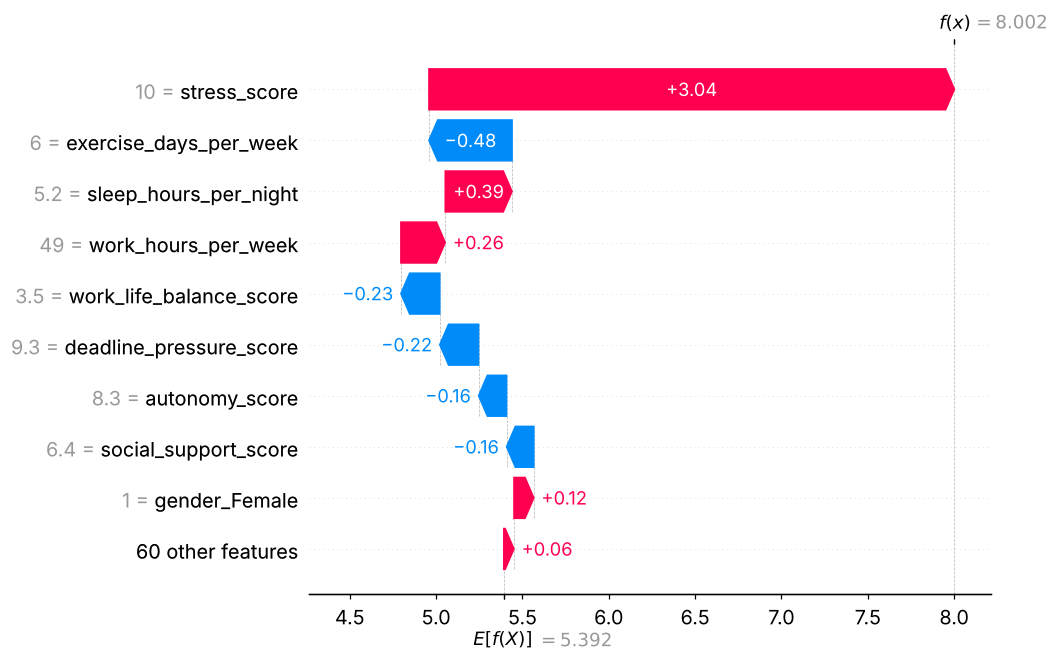

In [ ]:
# a high-risk employee: predicted score closest to 8
sample_pred = np.clip(hgb_model.predict(sample_t), 0, 10)
idx = int(np.argmin(np.abs(sample_pred - 8)))
print("actual score:", y_test.loc[sample.index[idx]], " predicted:", round(float(sample_pred[idx]), 2))
shap.plots.waterfall(sv[idx], max_display=10)

## 9. Saving the model for Bayyinah

We save the full pipeline (preprocessing + model) and a small metadata file. `burnout_predictor.py` loads both, predicts the score and level, and returns the top SHAP factors for that employee.

In [ ]:
joblib.dump(best_model, "burnout_regression_model.joblib")

meta = {
    "features": list(X_train.columns),
    "numeric_features": num_feats,
    "categorical_options": {c: sorted(X_train[c].unique().tolist())
                            for c in X_train.select_dtypes(exclude="number").columns},
    "level_cutoffs": {"Low": "<= 3.5", "Moderate": "<= 5.5", "High": "<= 7.0", "Severe": "> 7.0"},
    "best_params": {k.replace("model__", ""): (v.item() if hasattr(v, "item") else v)
                    for k, v in search.best_params_.items()},
    "test_metrics": test_results.loc["HGB tuned"].round(4).to_dict(),
    "sklearn_version": sklearn.__version__,
}
with open("burnout_model_meta.json", "w") as f:
    json.dump(meta, f, indent=2)

print("saved burnout_regression_model.joblib and burnout_model_meta.json")

saved burnout_regression_model.joblib and burnout_model_meta.json


In [ ]:
from burnout_predictor import BurnoutPredictor

predictor = BurnoutPredictor()

employee = X_test.iloc[0].to_dict()
print("actual score:", y_test.iloc[0])
predictor.predict(employee)

actual score: 0.4


{'burnout_score': 1.23,
 'burnout_level': 'Low',
 'average_score': 5.39,
 'top_factors': [{'feature': 'stress_score',
   'value': 2.4,
   'impact': -3.77,
   'effect': 'decreases'},
  {'feature': 'vacation_days_taken',
   'value': 18,
   'impact': -0.36,
   'effect': 'decreases'},
  {'feature': 'work_hours_per_week',
   'value': 44,
   'impact': -0.35,
   'effect': 'decreases'}],
 'missing_fields': []}

In [ ]:
# the website might not send every field; missing ones are filled by the imputers
partial = {k: employee[k] for k in ["stress_score", "work_hours_per_week", "sleep_hours_per_night",
                                     "vacation_days_taken", "seniority_level"]}
predictor.predict(partial)

{'burnout_score': 1.23,
 'burnout_level': 'Low',
 'average_score': 5.39,
 'top_factors': [{'feature': 'stress_score',
   'value': 2.4,
   'impact': -3.56,
   'effect': 'decreases'},
  {'feature': 'vacation_days_taken',
   'value': 18,
   'impact': -0.36,
   'effect': 'decreases'},
  {'feature': 'work_hours_per_week',
   'value': 44,
   'impact': -0.34,
   'effect': 'decreases'}],
 'missing_fields': ['age',
  'gender',
  'country',
  'job_role',
  'years_experience',
  'years_at_company',
  'company_size',
  'industry',
  'work_mode',
  'salary_usd',
  'meetings_per_day',
  'team_size',
  'exercise_days_per_week',
  'therapy_access',
  'uses_therapy',
  'ai_tools_daily',
  'manager_support_score',
  'work_life_balance_score',
  'job_satisfaction_score',
  'social_support_score',
  'deadline_pressure_score',
  'autonomy_score']}

**Using it in the Django backend**

```python
# services.py — load once when the server starts
from burnout_predictor import BurnoutPredictor
predictor = BurnoutPredictor("burnout_regression_model.joblib", "burnout_model_meta.json")

# views.py
@api_view(["POST"])
def predict_burnout(request):
    return Response(predictor.predict(request.data))
```

`preprocessing.py` must be in the same project, because the saved pipeline uses its `fix_logic` function.

## Summary

- The tuned HistGradientBoosting model explains about 87% of the variance in burnout scores on the test set, with an average error of about 0.78 points, against 2.21 for the Dummy baseline.
- Test results match cross-validation, so the model is not overfitting.
- stress_score dominates the predictions, followed by work hours, sleep and vacation days.
